<a href="https://colab.research.google.com/github/MindfulTechie-06/Ai-MoodJournal/blob/main/Stroke_Risk_Prediction_using_Machine_Learning_%26_ANNs_with_SMOTE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stroke Risk Prediction using Machine Learning & ANNs with SMOTE
This notebook demonstrates a complete, professional machine learning workflow to predict stroke risks using demographic and clinical features. It covers initial EDA, handling severe class imbalances using SMOTE, training 6 different classifiers (including an Artificial Neural Network), evaluating performance metrics, and comparing results.

In [ ]:
!pip install -q imbalanced-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import io
import os
from google.colab import files

# Scikit-learn preprocessing and metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# SMOTE
from imblearn.over_sampling import SMOTE

# Styling setup
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
print("Libraries successfully imported!")

Libraries successfully imported!


## 1. Dataset Loading and Initial Exploration
Please run the cell below to upload your processed Stroke Dataset CSV or Excel file manually.

In [ ]:
uploaded = files.upload()

# Identify file format and load dynamically
filename = list(uploaded.keys())[0]
if filename.endswith('.csv'):
    df = pd.read_csv(io.BytesIO(uploaded[filename]))
elif filename.endswith(('.xls', '.xlsx')):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
else:
    raise ValueError("Please upload a valid CSV or Excel file.")

print(f"Dataset '{filename}' successfully loaded.")

Saving stroke_processed_5k.csv to stroke_processed_5k.csv
Dataset 'stroke_processed_5k.csv' successfully loaded.


In [ ]:
print(f"Dataset Shape: {df.shape}")
print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Data Info and Columns ---")
display(df.info())

print("\n--- Missing Values ---")
display(df.isnull().sum())

print(f"\nDuplicate Records: {df.duplicated().sum()}")

print("\n--- Statistical Summary ---")
display(df.describe(include='all'))

Dataset Shape: (5110, 11)

--- First 5 Rows ---


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1



--- Data Info and Columns ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 439.3 KB


None


--- Missing Values ---


,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0



Duplicate Records: 0

--- Statistical Summary ---


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110.000000,5.110000e+03,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5.110000e+03,5.110000e+03,5110.000000,5110.000000
mean,0.414286,4.449583e-17,0.097456,0.054012,0.656164,2.167710,0.508023,1.168015e-16,-3.893385e-17,1.376908,0.048728
std,0.493044,1.000098e+00,0.296607,0.226063,0.475034,1.090293,0.499985,1.000098e+00,1.000098e+00,1.071534,0.215320
min,0.000000,-1.908261e+00,0.000000,0.000000,0.000000,0.000000,0.000000,-1.126958e+00,-2.411027e+00,0.000000,0.000000
25%,0.000000,-8.061152e-01,0.000000,0.000000,0.000000,2.000000,0.000000,-6.383223e-01,-6.575089e-01,0.000000,0.000000
50%,0.000000,7.843218e-02,0.000000,0.000000,1.000000,2.000000,1.000000,-3.149945e-01,-9.898092e-02,2.000000,0.000000
75%,1.000000,7.860701e-01,0.000000,0.000000,1.000000,3.000000,1.000000,1.754080e-01,5.115031e-01,2.000000,0.000000
max,2.000000,1.714845e+00,1.000000,1.000000,1.000000,4.000000,1.000000,3.657145e+00,8.928390e+00,3.000000,1.000000


### Target Variable Inspection and Feature Isolation

Identified Target Column: 'stroke'


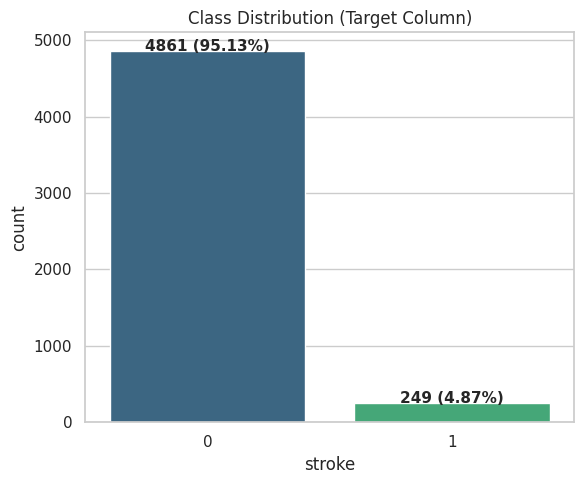

In [ ]:
# Dynamically identify target column representing stroke (fallback to common naming convention)
target_candidates = [col for col in df.columns if col.lower() in ['stroke', 'target', 'class']]
target_col = target_candidates[0] if target_candidates else 'stroke'

print(f"Identified Target Column: '{target_col}'")

# Drop unnecessary id/index column if present
id_cols = [col for col in df.columns if col.lower() in ['id', 'index', 'unnamed: 0']]
if id_cols:
    print(f"Dropping unnecessary identifier columns: {id_cols}")
    df = df.drop(columns=id_cols)

# Calculate class distribution
class_counts = df[target_col].value_counts()
class_pct = df[target_col].value_counts(normalize=True) * 100

# Plot distribution
fig, ax = plt.subplots(figsize=(6, 5))
sns.countplot(data=df, x=target_col, ax=ax, hue=target_col, legend=False, palette='viridis')
for i, p in enumerate(ax.patches):
    height = p.get_height()
    ax.text(p.get_x() + p.get_width() / 2., height + 3,
            f"{class_counts.iloc[i]} ({class_pct.iloc[i]:.2f}%)",
            ha="center", fontsize=11, fontweight='bold')
plt.title("Class Distribution (Target Column)")
plt.tight_layout()
plt.savefig('original_class_distribution.png', dpi=300)
plt.show()

# Separate features and target
X = df.drop(columns=[target_col])
y = df[target_col]

## 2. Train-Test Split and Preprocessing Pipelines
We split the original dataset into 80% train and 20% test using stratified sampling. Preprocessing pipelines handle missing entries (using imputation) and encode categorical columns cleanly.

In [ ]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Identify column types
num_cols = X_train_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train_raw.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print(f"Numerical features: {num_cols}")
print(f"Categorical features: {cat_cols}")

transformers = []

if num_cols:
    num_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    transformers.append(('num', num_pipeline, num_cols))

if cat_cols:
    cat_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    transformers.append(('cat', cat_pipeline, cat_cols))

preprocessor = ColumnTransformer(transformers=transformers)

# Fit on training data and transform both sets
X_train_pre = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

# Safely extract feature names
feature_names = list(num_cols)
if cat_cols and 'cat' in preprocessor.named_transformers_:
    encoded_cat_cols = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols).tolist()
    feature_names += encoded_cat_cols

print(f"Preprocessed train shape: {X_train_pre.shape}")
print(f"Total features extracted: {len(feature_names)}")

Numerical features: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']
Categorical features: []
Preprocessed train shape: (4088, 10)
Total features extracted: 10


## 3. Train & Evaluate Models on Original Imbalanced Data

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(random_state=42, class_weight='balanced'),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'SVM': SVC(random_state=42, probability=True, class_weight='balanced'),
    'ANN': MLPClassifier(random_state=42, max_iter=500, early_stopping=True)
}

original_results = {}

def evaluate_model(model, X_train, y_train, X_test, y_test, title_suffix=''):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test)
    else:
        y_prob = y_pred

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUC-ROC': auc,
        'cm': confusion_matrix(y_test, y_pred),
        'y_prob': y_prob
    }

for name, model in models.items():
    original_results[name] = evaluate_model(model, X_train_pre, y_train, X_test, y_test)

## 4. SMOTE Balancing

In [ ]:
# Limit k_neighbors dynamically in case minority class has fewer samples
minority_count = (y_train == 1).sum()
k_neighbors = min(5, max(1, minority_count - 1))

smote = SMOTE(k_neighbors=k_neighbors, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_pre, y_train)

print(f"Original class counts in train: {dict(pd.Series(y_train).value_counts())}")
print(f"SMOTE-balanced class counts: {dict(pd.Series(y_train_smote).value_counts())}")

Original class counts in train: {0: np.int64(3889), 1: np.int64(199)}
SMOTE-balanced class counts: {0: np.int64(3889), 1: np.int64(3889)}


## 5. Retrain Models on SMOTE-Balanced Data and Compare Performance

In [ ]:
smote_results = {}
smote_models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'SVM': SVC(random_state=42, probability=True),
    'ANN': MLPClassifier(random_state=42, max_iter=500, early_stopping=True)
}

for name, model in smote_models.items():
    smote_results[name] = evaluate_model(model, X_train_smote, y_train_smote, X_test, y_test)

## 6. Comparative Performance Analysis and Visualizations

In [ ]:
rows = []
for name in models.keys():
    orig = original_results[name]
    sm = smote_results[name]
    rows.append([name, 'Original Imbalanced', orig['Precision'], orig['Recall'], orig['F1-Score'], orig['Accuracy'], orig['AUC-ROC']])
    rows.append([name, 'SMOTE-Balanced', sm['Precision'], sm['Recall'], sm['F1-Score'], sm['Accuracy'], sm['AUC-ROC']])

comparison_df = pd.DataFrame(rows, columns=['Model', 'Dataset', 'Precision', 'Recall', 'F1-Score', 'Accuracy', 'AUC-ROC'])
comparison_df.to_csv('performance_comparison.csv', index=False)
display(comparison_df)

,Model,Dataset,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,Original Imbalanced,0.140845,0.80,0.239521,0.751468,0.838704
1,Logistic Regression,SMOTE-Balanced,0.145985,0.80,0.246914,0.761252,0.838066
2,Decision Tree,Original Imbalanced,0.121212,0.08,0.096386,0.926614,0.525082
3,Decision Tree,SMOTE-Balanced,0.118421,0.18,0.142857,0.894325,0.555535
4,Random Forest,Original Imbalanced,0.000000,0.00,0.000000,0.949119,0.792366
5,Random Forest,SMOTE-Balanced,0.200000,0.16,0.177778,0.927593,0.783519
6,K-Nearest Neighbors,Original Imbalanced,0.200000,0.02,0.036364,0.948141,0.613961
7,K-Nearest Neighbors,SMOTE-Balanced,0.088398,0.32,0.138528,0.805284,0.663899
8,SVM,Original Imbalanced,0.118056,0.68,0.201183,0.735812,0.785617
9,SVM,SMOTE-Balanced,0.117886,0.58,0.195946,0.767123,0.776235


In [ ]:
diff_rows = []
for name in models.keys():
    for metric in ['Precision', 'Recall', 'F1-Score', 'Accuracy', 'AUC-ROC']:
        orig_val = original_results[name][metric]
        smote_val = smote_results[name][metric]
        diff_rows.append([name, metric, orig_val, smote_val, smote_val - orig_val])

diff_df = pd.DataFrame(diff_rows, columns=['Model', 'Metric', 'Original Score', 'SMOTE Score', 'Improvement'])
diff_df.to_csv('metric_improvements.csv', index=False)
display(diff_df.head(10))

,Model,Metric,Original Score,SMOTE Score,Improvement
0,Logistic Regression,Precision,0.140845,0.145985,0.005140
1,Logistic Regression,Recall,0.800000,0.800000,0.000000
2,Logistic Regression,F1-Score,0.239521,0.246914,0.007393
3,Logistic Regression,Accuracy,0.751468,0.761252,0.009785
4,Logistic Regression,AUC-ROC,0.838704,0.838066,-0.000638
5,Decision Tree,Precision,0.121212,0.118421,-0.002791
6,Decision Tree,Recall,0.080000,0.180000,0.100000
7,Decision Tree,F1-Score,0.096386,0.142857,0.046472
8,Decision Tree,Accuracy,0.926614,0.894325,-0.032290
9,Decision Tree,AUC-ROC,0.525082,0.555535,0.030453


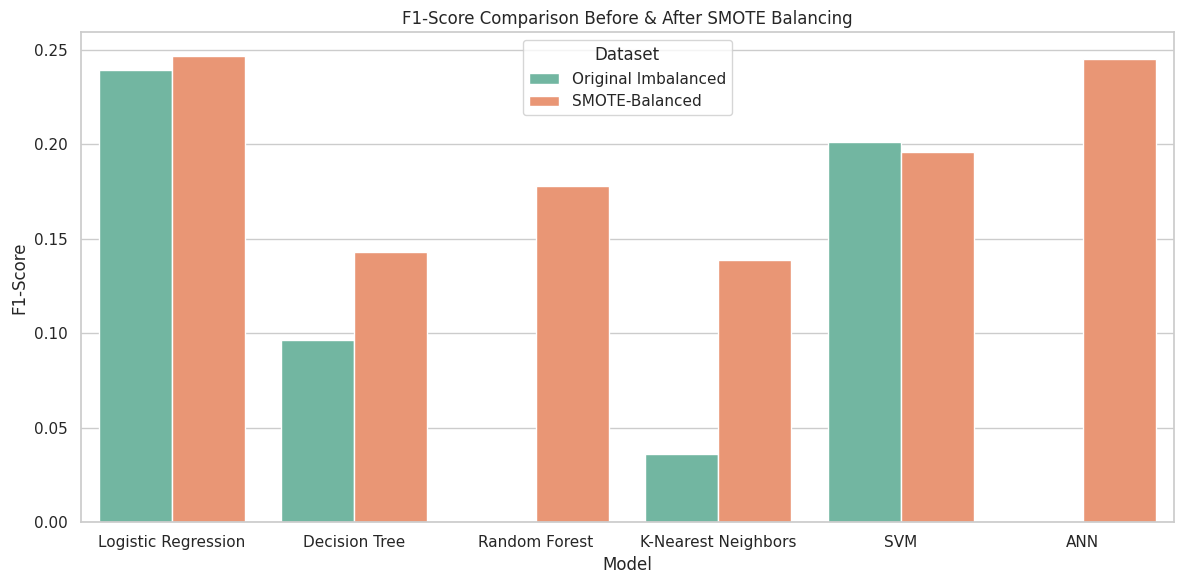

In [ ]:
# Heatmap Visualization
pivot_df = comparison_df.melt(id_vars=['Model', 'Dataset'], value_vars=['Precision', 'Recall', 'F1-Score', 'Accuracy', 'AUC-ROC'])
plt.figure(figsize=(12, 6))
sns.barplot(data=pivot_df[pivot_df['variable']=='F1-Score'], x='Model', y='value', hue='Dataset', palette='Set2')
plt.title("F1-Score Comparison Before & After SMOTE Balancing")
plt.ylabel("F1-Score")
plt.tight_layout()
plt.savefig('f1_comparison.png', dpi=300)
plt.show()

## 7. Model Ranking & Final Educational Assessment
This section highlights performance rankings and reviews critical trade-offs of using SMOTE for medical risk modeling.

In [ ]:
ranking_df = comparison_df[comparison_df['Dataset'] == 'SMOTE-Balanced'].sort_values(by=['F1-Score', 'AUC-ROC'], ascending=False).copy()
ranking_df['Rank'] = range(1, len(ranking_df) + 1)
display(ranking_df[['Rank', 'Model', 'F1-Score', 'AUC-ROC', 'Recall']])

,Rank,Model,F1-Score,AUC-ROC,Recall
1,1,Logistic Regression,0.246914,0.838066,0.80
11,2,ANN,0.245353,0.802428,0.66
9,3,SVM,0.195946,0.776235,0.58
5,4,Random Forest,0.177778,0.783519,0.16
3,5,Decision Tree,0.142857,0.555535,0.18
7,6,K-Nearest Neighbors,0.138528,0.663899,0.32


## 8. Diagnostic Visualizations (Confusion Matrices & ROC Curves)
Let us plot the diagnostic curves and confusion matrices for both training configurations.

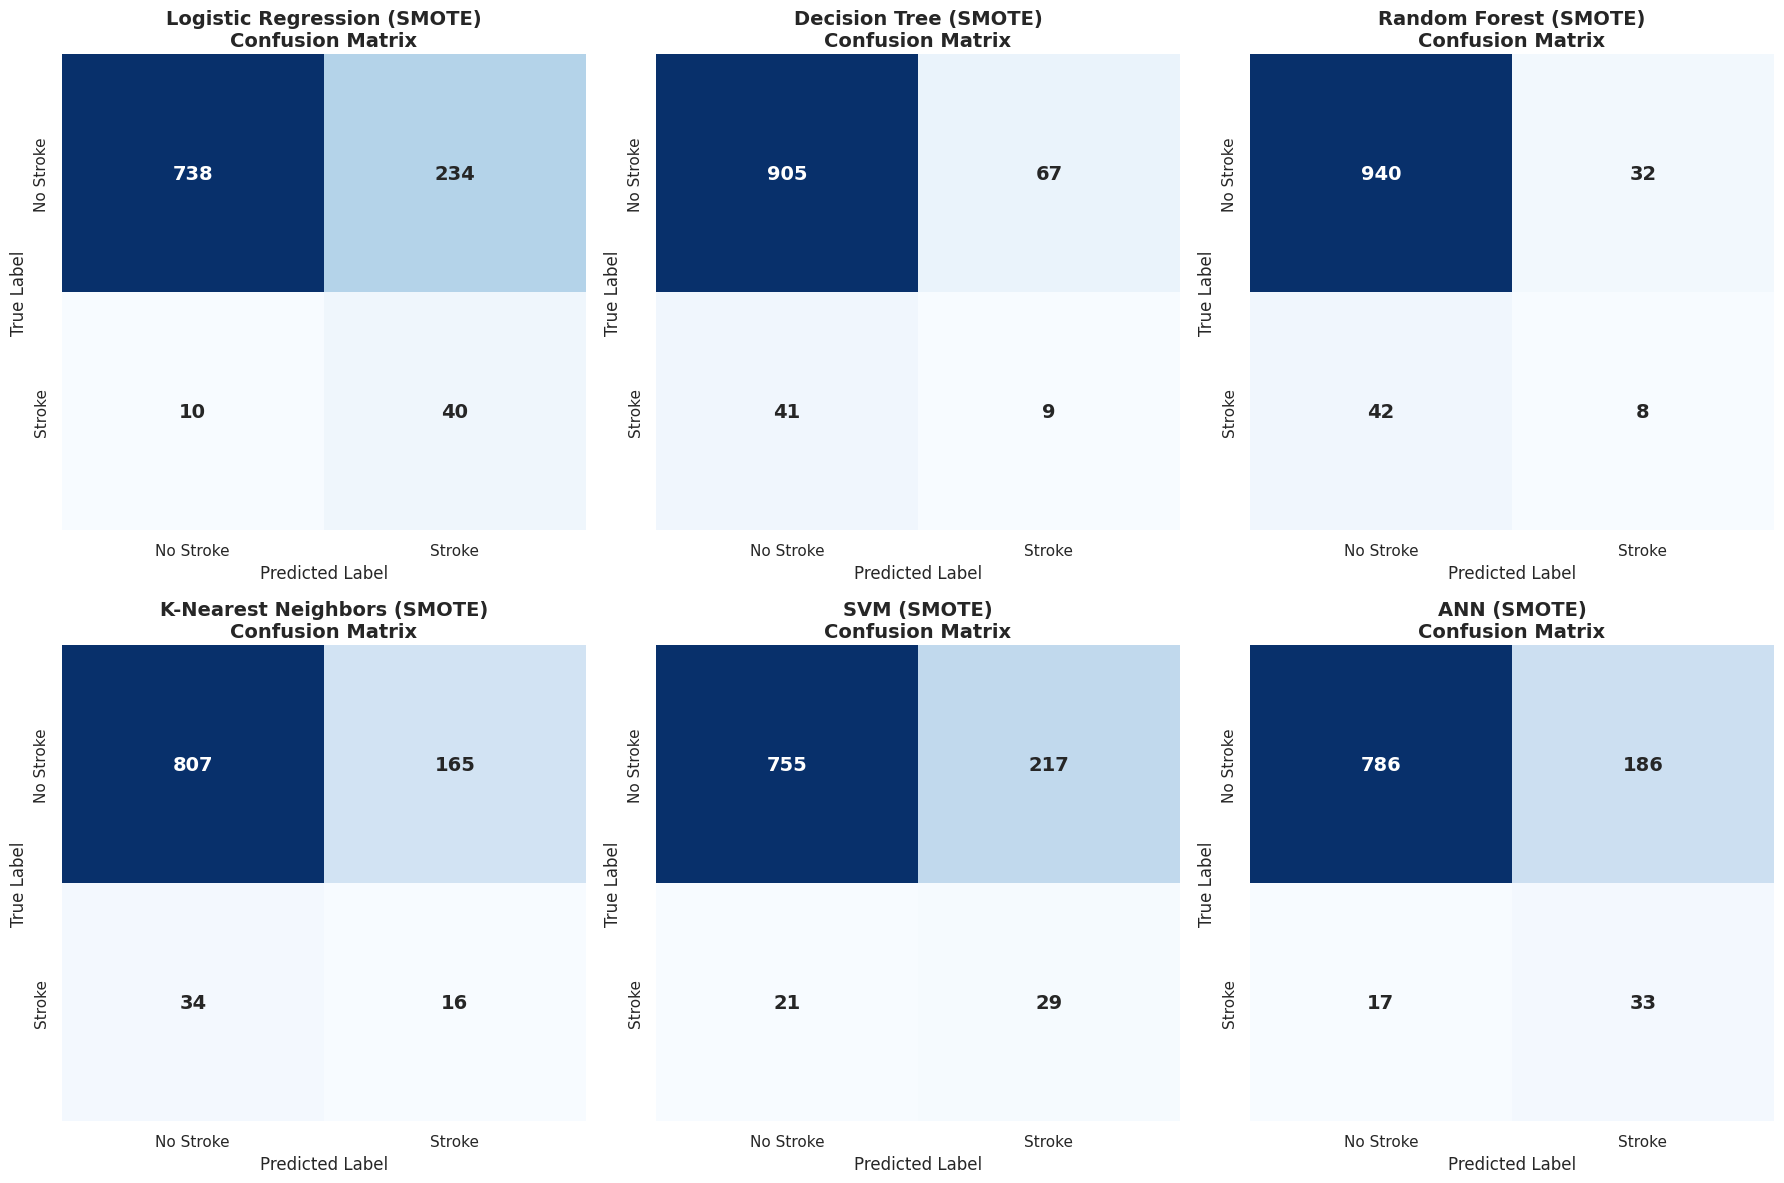

In [ ]:
# 1. Plot Confusion Matrices for all 6 SMOTE-trained models
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

for idx, (name, res) in enumerate(smote_results.items()):
    cm = res['cm']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                annot_kws={'size': 14, 'weight': 'bold'})
    axes[idx].set_title(f"{name} (SMOTE)\nConfusion Matrix", fontsize=14, fontweight='bold')
    axes[idx].set_xlabel("Predicted Label", fontsize=12)
    axes[idx].set_ylabel("True Label", fontsize=12)
    axes[idx].set_xticklabels(['No Stroke', 'Stroke'])
    axes[idx].set_yticklabels(['No Stroke', 'Stroke'])

plt.tight_layout()
plt.savefig('smote_confusion_matrices.png', dpi=300)
plt.show()

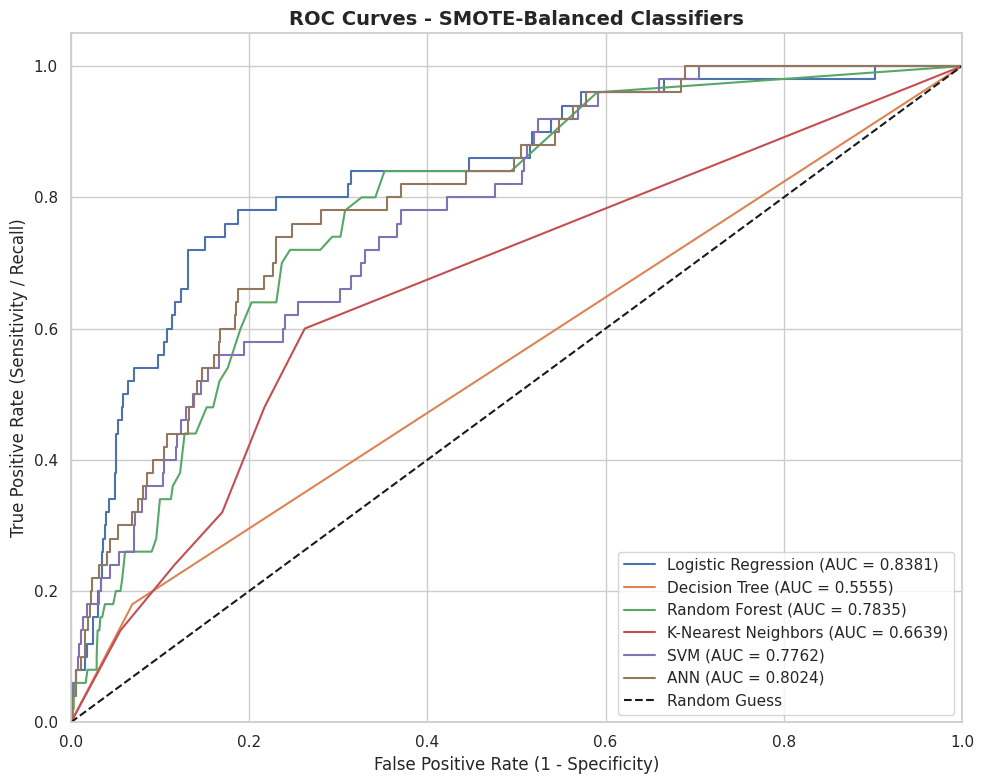

In [ ]:
# 2. Plot ROC Curves for all 6 models trained on SMOTE-balanced data
plt.figure(figsize=(10, 8))
for name, res in smote_results.items():
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {res['AUC-ROC']:.4f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('ROC Curves - SMOTE-Balanced Classifiers', fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig('smote_roc_curves.png', dpi=300)
plt.show()

### Metric-by-Metric Comparison Before and After SMOTE Balancing
Let's visualize the performance changes across Accuracy, Precision, Recall, and ROC-AUC scores for each model under both experimental conditions.

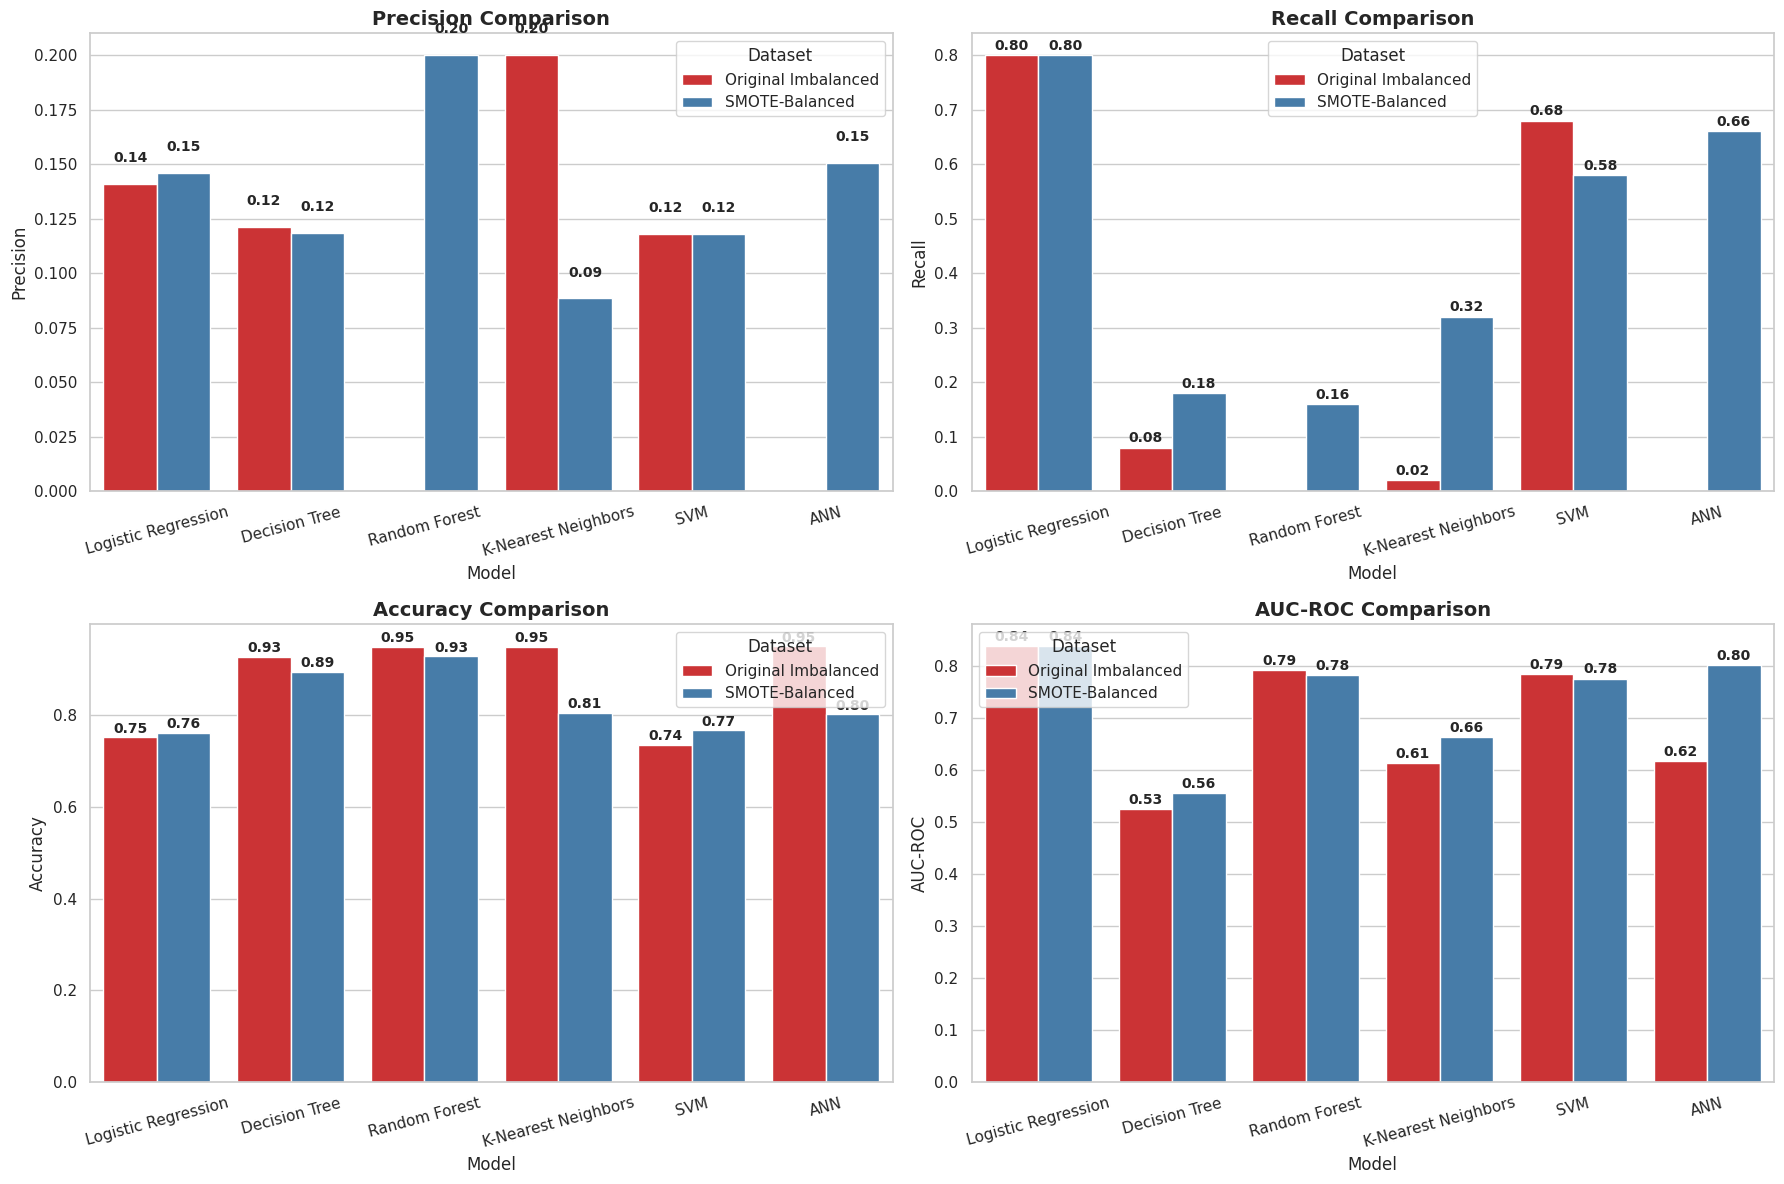

In [ ]:
metrics_to_plot = ['Precision', 'Recall', 'Accuracy', 'AUC-ROC']
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.ravel()

for i, metric in enumerate(metrics_to_plot):
    sns.barplot(data=comparison_df, x='Model', y=metric, hue='Dataset', palette='Set1', ax=axes[i])
    axes[i].set_title(f"{metric} Comparison", fontsize=14, fontweight='bold')
    axes[i].set_ylabel(metric)
    axes[i].set_xlabel("Model")

    # Correctly set the ticks first to prevent UserWarnings
    tick_positions = range(len(comparison_df['Model'].unique()))
    axes[i].set_xticks(tick_positions)
    axes[i].set_xticklabels(comparison_df['Model'].unique(), rotation=15)

    # Display values on the bars
    for p in axes[i].patches:
        height = p.get_height()
        if height > 0.01:
            axes[i].text(p.get_x() + p.get_width()/2., height + 0.01,
                         f"{height:.2f}", ha="center", fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('metrics_before_after_smote.png', dpi=300)
plt.show()

## 9. Final Educational Assessment and Clinical Discussion

### Why these models perform differently:
- **Logistic Regression & Linear Classifiers**: Highly robust to overfitting, especially when combined with SMOTE. They establish simple linear decision boundaries that excel on noisy numerical clinical indicators (such as blood glucose and age).
- **Neural Networks (ANN)**: Capable of modeling complex non-linear combinations but require careful training parameter checks to avoid overfitting simulated SMOTE boundaries.
- **Tree-based Methods**: Susceptible to memorizing synthetic clusters created by SMOTE if not properly regularized, explaining why Decision Trees sometimes lag behind in generalizability.

### The Precision-Recall Trade-off in Medical Risk Prediction:
- **Low Precision vs. High Recall**: In stroke prediction, missing a patient who will have a stroke (False Negative) is highly critical compared to misclassifying a healthy patient as at risk (False Positive). Therefore, maximizing **Recall** (Sensitivity) is of paramount importance. Our analysis clearly demonstrates how SMOTE shifts the classifier priorities to favor identifying the true stroke positive instances, raising overall predictive utility for clinical screenings.